# Skeleton action recognition: LSTM vs LSTM + attention

Pipeline: video -> MediaPipe skeleton -> clean and normalise -> sliding windows -> three small models -> test on the long video.

| Model | What it is |
|---|---|
| A | LSTM only (baseline) |
| B | LSTM + temporal attention (which frames matter) |
| C | LSTM + spatial attention (which joints matter) |

**Before running:** turn the internet ON in the notebook settings (needed once, to install MediaPipe and download the pose model). Then use *Run All*.

## 1. Install and import

In [1]:
# MediaPipe is not pre-installed on Kaggle. Dependency warnings printed here are normal.
!pip install -q mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 44.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 7.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [2]:
import os
import copy
import random
import urllib.request

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Patch

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("mediapipe", mp.__version__, "| torch", torch.__version__, "| device:", DEVICE)

mediapipe 1.1.0 | torch 2.11.0+cu128 | device: cuda


## 2. Settings

Everything you may want to change is in this one cell.

In [3]:
# ---------------------------------------------------------------- paths
TRAIN_DIR  = "/kaggle/input/datasets/absoo2810/train-dataset"               # 6 videos, file name = action name
TEST_VIDEO = "/kaggle/input/datasets/absoo2810/test-video2/test video.mp4"  # the long video
WORK_DIR   = "/kaggle/working"                                              # skeletons and results are saved here

# ---------------------------------------------------------------- classes
# The label of each training video is its file name without ".mp4".
CLASSES = ["clap", "phone call", "sit down", "spray perfume", "stand up", "wave"]

# ---------------------------------------------------------------- windows
TARGET_FPS       = 20     # every skeleton sequence is resampled to this frame rate
WINDOW_SEC       = 1.5    # length of one window (one training example)
TRAIN_STRIDE_SEC = 0.2    # step between two training windows
TEST_STRIDE_SEC  = 0.2    # step between two windows on the long video
VAL_FRACTION     = 0.3    # the last 30% of each training video is kept for validation

# ---------------------------------------------------------------- model and training
HIDDEN          = 64      # LSTM size (kept small because the dataset is small)
DROPOUT         = 0.3
EPOCHS          = 60
PATIENCE        = 12      # stop if validation loss has not improved for this many epochs
BATCH_SIZE      = 32
STEPS_PER_EPOCH = 30
LR              = 1e-3
WEIGHT_DECAY    = 1e-4
SEEDS           = [0, 1, 2]   # each model is trained once per seed, so a result is not luck

# ---------------------------------------------------------------- long video
SMOOTH_SEC      = 1.0     # predictions are averaged over this much time
MIN_SEGMENT_SEC = 2.0     # detected segments shorter than this are merged into a neighbour
TEST_START_SEC  = 8.0     # the long video is analysed from this second (before it the camera is being set up)
CONF_THRESHOLD  = 0.5     # below this confidence the window is labelled "unknown"

# Order of the actions in the long video (used only to check the predicted order).
EXPECTED_ORDER = ["wave", "stand up", "clap", "phone call", "spray perfume", "clap"]

# OPTIONAL: real timings of the long video as (start_second, end_second, "label").
# Fill this in to get accuracy and F1 on the long video. Example:
# GROUND_TRUTH = [(4.0, 9.5, "wave"), (9.5, 12.0, "stand up"), (12.0, 17.0, "clap")]
GROUND_TRUTH = []

# ---------------------------------------------------------------- derived values (do not edit)
WIN          = int(round(WINDOW_SEC * TARGET_FPS))                 # frames per window
TRAIN_STRIDE = max(1, int(round(TRAIN_STRIDE_SEC * TARGET_FPS)))
TEST_STRIDE  = max(1, int(round(TEST_STRIDE_SEC * TARGET_FPS)))
SKEL_DIR     = os.path.join(WORK_DIR, "skeletons")
os.makedirs(SKEL_DIR, exist_ok=True)

# One fixed colour per class, used in every plot.
CLASS_COLORS = {
    "clap": "#2a78d6", "phone call": "#eb6834", "sit down": "#1baf7a",
    "spray perfume": "#eda100", "stand up": "#e87ba4", "wave": "#008300",
    "unknown": "#c3c2b7",
}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
BLUE_MAP = LinearSegmentedColormap.from_list("blue_ramp", ["#ffffff", "#cde2fb", "#3987e5", "#0d366b"])
DIVERGING_MAP = LinearSegmentedColormap.from_list("orange_grey_blue", ["#eb6834", "#f0efec", "#2a78d6"])

print(f"window = {WIN} frames ({WINDOW_SEC}s at {TARGET_FPS} fps), train stride = {TRAIN_STRIDE} frames")

window = 30 frames (1.5s at 20 fps), train stride = 4 frames


## 3. Skeleton extraction (MediaPipe)

Each video is read frame by frame and MediaPipe returns 33 body landmarks per frame.
We use the *world* landmarks: 3D positions in metres, measured from the hips, so they do not change when the person stands closer to or further from the camera.

The result is saved to `/kaggle/working/skeletons`, so MediaPipe runs only the first time.

In [4]:
# ---------------------------------------------------------------- pose model file
MODEL_URL = ("https://storage.googleapis.com/mediapipe-models/pose_landmarker/"
             "pose_landmarker_full/float16/latest/pose_landmarker_full.task")
MODEL_PATH = os.path.join(WORK_DIR, "pose_landmarker_full.task")


def ensure_pose_model():
    # Download the MediaPipe pose model once.
    if not os.path.exists(MODEL_PATH):
        print("downloading pose model ...")
        urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)


# ---------------------------------------------------------------- one video -> skeleton
def extract_skeleton(video_path, cache_path):
    # Returns (xyz, fps).
    #   xyz: array (n_frames, 33, 3); a frame is NaN when no person was detected.
    #   fps: frame rate of the video.
    if os.path.exists(cache_path):                       # already extracted in an earlier run
        saved = np.load(cache_path)
        return saved["xyz"], float(saved["fps"])

    ensure_pose_model()
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise FileNotFoundError(f"cannot open video: {video_path}")
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps != fps or fps <= 0:                # missing or NaN frame rate
        fps = 30.0

    options = vision.PoseLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=MODEL_PATH),
        running_mode=vision.RunningMode.VIDEO,           # video mode tracks the person between frames
        num_poses=1,
    )

    frames = []
    with vision.PoseLandmarker.create_from_options(options) as landmarker:
        i = 0
        while True:
            ok, frame_bgr = cap.read()
            if not ok:
                break
            frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
            image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
            result = landmarker.detect_for_video(image, int(i * 1000 / fps))   # timestamp in ms
            if result.pose_world_landmarks:
                person = result.pose_world_landmarks[0]
                frames.append([[lm.x, lm.y, lm.z] for lm in person])
            else:
                frames.append([[np.nan] * 3] * 33)       # nobody detected in this frame
            i += 1
    cap.release()

    if len(frames) == 0:
        raise RuntimeError(f"no frames could be read from: {video_path}")
    xyz = np.asarray(frames, dtype=np.float32)
    np.savez(cache_path, xyz=xyz, fps=fps)
    return xyz, float(fps)


# ---------------------------------------------------------------- find the 6 training videos
def find_train_videos(train_dir):
    # Maps each class name to its video file, using the file name as the label.
    found = {}
    for root, _, files in os.walk(train_dir):
        for name in sorted(files):
            if name.lower().endswith((".mp4", ".mov", ".avi", ".mkv")):
                label = os.path.splitext(name)[0].strip().lower().replace("_", " ").replace("-", " ")
                if label in CLASSES:
                    found[label] = os.path.join(root, name)
    missing = [c for c in CLASSES if c not in found]
    if missing:
        raise FileNotFoundError(f"no training video found for: {missing} (looked in {train_dir})")
    return found


# ---------------------------------------------------------------- run on all videos
train_videos = find_train_videos(TRAIN_DIR)
raw = {}                                                 # name -> (xyz, fps)
for label in CLASSES:
    cache = os.path.join(SKEL_DIR, f"train_{label.replace(' ', '_')}.npz")
    raw[label] = extract_skeleton(train_videos[label], cache)
raw["__test__"] = extract_skeleton(TEST_VIDEO, os.path.join(SKEL_DIR, "test_video.npz"))

report = []
for name, (xyz, fps) in raw.items():
    detected = ~np.isnan(xyz[:, 0, 0])
    report.append({"video": "long test video" if name == "__test__" else name,
                   "frames": len(xyz), "fps": round(fps, 2),
                   "seconds": round(len(xyz) / fps, 1),
                   "person detected %": round(100 * detected.mean(), 1)})
pd.DataFrame(report)

downloading pose model ...


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1791711416.326892     174 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791711416.372029     174 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791711416.453928     175 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.
W0000 00:00:1791711434.255555     190 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1791711434.298839     191 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:0

,video,frames,fps,seconds,person detected %
0,clap,619,60.00,10.3,100.0
1,phone call,1877,60.00,31.3,97.0
2,sit down,843,60.00,14.1,100.0
3,spray perfume,703,60.00,11.7,100.0
4,stand up,217,60.00,3.6,100.0
5,wave,660,60.00,11.0,100.0
6,long test video,4677,59.92,78.0,100.0


## 4. Clean and normalise

1. Fill the frames where the person was not detected (linear interpolation).
2. Keep 25 joints: nose, both ears and the body. Eyes and mouth are dropped; the ears stay because they matter for *phone call*.
3. Centre the body on the middle of the hips and divide by the torso length, so the skeleton always has the same size.
4. Light smoothing (MediaPipe output shakes a little).
5. Resample to the same frame rate for every video.

In [5]:
# ---------------------------------------------------------------- joints we keep
MP_NAMES = ["nose", "left_eye_inner", "left_eye", "left_eye_outer", "right_eye_inner", "right_eye",
            "right_eye_outer", "left_ear", "right_ear", "mouth_left", "mouth_right",
            "left_shoulder", "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist",
            "left_pinky", "right_pinky", "left_index", "right_index", "left_thumb", "right_thumb",
            "left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle",
            "left_heel", "right_heel", "left_foot_index", "right_foot_index"]
KEEP = [0, 7, 8] + list(range(11, 33))
JOINT_NAMES = [MP_NAMES[i] for i in KEEP]
N_JOINTS = len(JOINT_NAMES)                              # 25
J = {name: i for i, name in enumerate(JOINT_NAMES)}      # joint name -> index


def _swap_side(name):
    if name.startswith("left_"):
        return "right_" + name[5:]
    if name.startswith("right_"):
        return "left_" + name[6:]
    return name


# For mirroring: index of the opposite-side joint (left wrist <-> right wrist, ...).
MIRROR_INDEX = np.array([J[_swap_side(n)] for n in JOINT_NAMES])


# ---------------------------------------------------------------- cleaning steps
def fill_missing(xyz):
    # Replace NaN frames by interpolating between the nearest detected frames.
    n = len(xyz)
    flat = xyz.reshape(n, -1).astype(np.float64).copy()
    valid = ~np.isnan(flat[:, 0])
    if valid.sum() == 0:
        raise RuntimeError("MediaPipe did not detect a person in any frame of this video")
    idx = np.arange(n)
    for c in range(flat.shape[1]):
        flat[:, c] = np.interp(idx, idx[valid], flat[valid, c])
    return flat.reshape(xyz.shape)


def smooth(seq, k=3):
    # Moving average over k frames.
    pad = k // 2
    padded = np.pad(seq, ((pad, pad), (0, 0), (0, 0)), mode="edge")
    return np.mean([padded[i:i + len(seq)] for i in range(k)], axis=0)


def resample(seq, fps, target_fps):
    # Change the frame rate of a sequence by linear interpolation in time.
    n = len(seq)
    t_old = np.arange(n) / fps
    t_new = np.arange(int(np.floor(t_old[-1] * target_fps)) + 1) / target_fps
    flat = seq.reshape(n, -1)
    out = np.stack([np.interp(t_new, t_old, flat[:, c]) for c in range(flat.shape[1])], axis=1)
    return out.reshape(len(t_new), *seq.shape[1:])


def preprocess(xyz, fps):
    # Raw MediaPipe output (n, 33, 3) -> clean sequence (m, 25, 3) at TARGET_FPS.
    seq = fill_missing(xyz)[:, KEEP, :]                                  # steps 1 and 2
    hip_mid = (seq[:, J["left_hip"]] + seq[:, J["right_hip"]]) / 2
    shoulder_mid = (seq[:, J["left_shoulder"]] + seq[:, J["right_shoulder"]]) / 2
    seq = seq - hip_mid[:, None, :]                                      # step 3: centre
    torso = np.median(np.linalg.norm(shoulder_mid - hip_mid, axis=1))    # one body size per video
    seq = seq / max(torso, 1e-6)                                         # step 3: scale
    seq = smooth(seq, k=3)                                               # step 4
    seq = resample(seq, fps, TARGET_FPS)                                 # step 5
    return seq.astype(np.float32)


sequences = {name: preprocess(xyz, fps) for name, (xyz, fps) in raw.items()}
for name, seq in sequences.items():
    print(f"{name:15s} -> {seq.shape[0]:5d} frames x {seq.shape[1]} joints x {seq.shape[2]} coords")

clap            ->   207 frames x 25 joints x 3 coords
phone call      ->   626 frames x 25 joints x 3 coords
sit down        ->   281 frames x 25 joints x 3 coords
spray perfume   ->   235 frames x 25 joints x 3 coords
stand up        ->    73 frames x 25 joints x 3 coords
wave            ->   220 frames x 25 joints x 3 coords
__test__        ->  1561 frames x 25 joints x 3 coords


## 5. Windows and train / validation split

Each training video is split **by time**: the first 70% is used for training and the last 30% for validation.
Windows never cross that border, so a validation window shares no frame with a training window.

*stand up* is only 3 seconds long, so it gives very few windows. The table below shows the imbalance; the training loop compensates by showing every class equally often.

In [6]:
def pad_to_window(seq):
    # A piece shorter than one window is extended by repeating its last frame.
    if len(seq) >= WIN:
        return seq
    return np.pad(seq, ((0, WIN - len(seq)), (0, 0), (0, 0)), mode="edge")


segments = []          # each item: {"data": (frames, 25, 3), "label": int, "split": ..., "padded": bool}
index = {"train": [], "val": []}   # each item: (segment id, first frame of the window)

for label_id, label in enumerate(CLASSES):
    seq = sequences[label]
    cut = int(round(len(seq) * (1 - VAL_FRACTION)))
    for split, piece in (("train", seq[:cut]), ("val", seq[cut:])):
        padded = len(piece) < WIN
        piece = pad_to_window(piece)
        seg_id = len(segments)
        segments.append({"data": piece, "label": label_id, "split": split, "padded": padded})
        for start in range(0, len(piece) - WIN + 1, TRAIN_STRIDE):
            index[split].append((seg_id, start))

counts = pd.DataFrame(
    {split: pd.Series([segments[s]["label"] for s, _ in index[split]]).value_counts()
     for split in ("train", "val")}).reindex(range(len(CLASSES))).fillna(0).astype(int)
counts.index = CLASSES
counts.columns = ["train windows", "val windows"]
counts

,train windows,val windows
clap,29,9
phone call,103,40
sit down,42,14
spray perfume,34,11
stand up,6,1
wave,32,10


## 6. Features and augmentation

**Features.** For every joint in every frame we give the model 6 numbers: its position (x, y, z) and its velocity (how much it moved since the previous frame). Input shape of one example: `(30 frames, 25 joints, 6)`.

**Augmentation (training only).** Each time a window is drawn it is changed a little, so the model never sees exactly the same example twice: speed (0.8x to 1.2x), left/right mirror, small rotation, small size change, small shake on the joints.

In [7]:
def augment_window(seq, start):
    # Cut a window from seq starting near `start` and return a randomly changed copy (WIN, 25, 3).
    # 1) speed: take a slightly longer or shorter piece, then stretch it back to WIN frames
    span = int(round(WIN * np.random.uniform(0.8, 1.2)))
    span = min(span, len(seq))
    start = max(0, min(start, len(seq) - span))
    piece = seq[start:start + span]
    pos = np.linspace(0, span - 1, WIN)
    lo = np.floor(pos).astype(int)
    hi = np.minimum(lo + 1, span - 1)
    w = (pos - lo)[:, None, None]
    win = piece[lo] * (1 - w) + piece[hi] * w

    # 2) mirror left and right (a wave with the left hand is still a wave)
    if np.random.rand() < 0.5:
        win = win[:, MIRROR_INDEX, :].copy()
        win[..., 0] *= -1

    # 3) rotate the body around the vertical axis by up to 20 degrees (slightly different camera angle)
    a = np.deg2rad(np.random.uniform(-20, 20))
    x, z = win[..., 0].copy(), win[..., 2].copy()
    win[..., 0] = x * np.cos(a) + z * np.sin(a)
    win[..., 2] = -x * np.sin(a) + z * np.cos(a)

    # 4) size and 5) small shake
    win = win * np.random.uniform(0.9, 1.1)
    win = win + np.random.normal(0, 0.01, win.shape)
    return win.astype(np.float32)


def velocity(win):
    # Movement of every joint since the previous frame (first frame = 0).
    return np.diff(win, axis=0, prepend=win[:1])


# One number that brings velocities to the same range as positions (measured on training data only).
VEL_STD = float(np.std(np.concatenate(
    [velocity(segments[s]["data"][st:st + WIN]).ravel() for s, st in index["train"]])))


def make_features(win):
    # (WIN, 25, 3) positions -> (WIN, 25, 6) = position + scaled velocity.
    return np.concatenate([win, velocity(win) / VEL_STD], axis=-1).astype(np.float32)


class WindowDataset(Dataset):
    # Serves (features, label) pairs. With augment=True every draw is a new random variation.
    def __init__(self, split, augment):
        self.items = index[split]
        self.augment = augment

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        seg_id, start = self.items[i]
        seq = segments[seg_id]["data"]
        win = augment_window(seq, start) if self.augment else seq[start:start + WIN]
        return torch.from_numpy(make_features(win)), segments[seg_id]["label"]


train_set = WindowDataset("train", augment=True)
val_set = WindowDataset("val", augment=False)
x0, y0 = train_set[0]
print("one example:", tuple(x0.shape), "| label:", CLASSES[y0], "| velocity scale:", round(VEL_STD, 4))

one example: (30, 25, 6) | label: clap | velocity scale: 0.0272


## 7. The three models

All three share the same LSTM and the same classifier. Only one part differs, so any change in the results comes from that part.

- **A:** the LSTM reads the window and the decision is taken from its *last* output only.
- **B (temporal attention):** every frame's LSTM output gets an importance score; the decision is taken from the weighted average of *all* outputs.
- **C (spatial attention):** before the LSTM, every joint gets an importance score in each frame; important joints are amplified and the rest are turned down. One small scorer is shared by all joints and looks at one joint at a time (its position and velocity). This is a simplified version of the joint attention in STA-LSTM.

In [8]:
class SkeletonLSTM(nn.Module):
    def __init__(self, temporal_att=False, spatial_att=False,
                 n_joints=N_JOINTS, n_feat=6, hidden=HIDDEN, n_classes=len(CLASSES), dropout=DROPOUT):
        super().__init__()
        in_dim = n_joints * n_feat
        self.temporal_att, self.spatial_att = temporal_att, spatial_att

        if spatial_att:      # one small network scores every joint from that joint's own 6 numbers
            self.joint_scorer = nn.Sequential(nn.Linear(n_feat, 16), nn.Tanh(), nn.Linear(16, 1))
        self.lstm = nn.LSTM(in_dim, hidden, batch_first=True)
        if temporal_att:     # one score per frame, computed from the LSTM output of that frame
            self.time_scorer = nn.Sequential(nn.Linear(hidden, 32), nn.Tanh(), nn.Linear(32, 1))
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, n_classes)

    def forward(self, x):
        # x: (batch, frames, joints, 6)
        B, T, Jn, F = x.shape
        joint_w = time_w = None

        if self.spatial_att:
            scores = self.joint_scorer(x).squeeze(-1)                    # (B, T, joints)
            joint_w = torch.softmax(scores, dim=-1)                      # weights of a frame sum to 1
            x = x * joint_w.unsqueeze(-1) * Jn                           # x Jn: an equal share stays at 1

        out, _ = self.lstm(x.reshape(B, T, Jn * F))                      # (B, T, hidden)

        if self.temporal_att:
            time_w = torch.softmax(self.time_scorer(out).squeeze(-1), dim=1)   # (B, T), sums to 1
            summary = (out * time_w.unsqueeze(-1)).sum(dim=1)            # weighted average of all frames
        else:
            summary = out[:, -1]                                         # last frame only

        logits = self.classifier(self.dropout(summary))
        return logits, {"time": time_w, "joint": joint_w}


MODEL_CONFIGS = {
    "A: LSTM":                      dict(temporal_att=False, spatial_att=False),
    "B: LSTM + temporal attention": dict(temporal_att=True,  spatial_att=False),
    "C: LSTM + spatial attention":  dict(temporal_att=False, spatial_att=True),
    # "D: LSTM + both":             dict(temporal_att=True,  spatial_att=True),   # optional 4th model
}

for name, cfg in MODEL_CONFIGS.items():
    n_params = sum(p.numel() for p in SkeletonLSTM(**cfg).parameters())
    print(f"{name:32s} {n_params:,} parameters")

A: LSTM                          55,686 parameters
B: LSTM + temporal attention     57,799 parameters
C: LSTM + spatial attention      55,815 parameters


## 8. Training

- Every class is shown equally often (balanced sampling), which compensates for the very short *stand up* video.
- After each epoch the model is checked on the validation windows; the best version is kept and training stops early when it no longer improves.
- Each model is trained once per seed.

In [9]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


@torch.no_grad()
def evaluate(model, loader):
    # Returns (loss, accuracy, macro F1, true labels, predicted labels).
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        logits.append(model(x.to(DEVICE))[0].cpu())
        labels.append(y)
    logits, labels = torch.cat(logits), torch.cat(labels)
    loss = nn.functional.cross_entropy(logits, labels).item()
    pred = logits.argmax(1).numpy()
    true = labels.numpy()
    f1 = f1_score(true, pred, average="macro", labels=range(len(CLASSES)), zero_division=0)
    return loss, accuracy_score(true, pred), f1, true, pred


def train_model(name, seed):
    set_seed(seed)
    model = SkeletonLSTM(**MODEL_CONFIGS[name]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    # balanced sampling: a window from a rare class is drawn more often
    labels = np.array([segments[s]["label"] for s, _ in index["train"]])
    class_count = np.bincount(labels, minlength=len(CLASSES))
    sampler = WeightedRandomSampler(weights=1.0 / class_count[labels],
                                    num_samples=STEPS_PER_EPOCH * BATCH_SIZE, replacement=True,
                                    generator=torch.Generator().manual_seed(seed))
    train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, sampler=sampler)
    val_loader = DataLoader(val_set, batch_size=256)

    best_loss, best_state, best_epoch, waited = float("inf"), None, 0, 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for x, y in train_loader:
            optimizer.zero_grad()
            loss = nn.functional.cross_entropy(model(x.to(DEVICE))[0], y.to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        val_loss = evaluate(model, val_loader)[0]
        if val_loss < best_loss - 1e-4:                  # improved: remember this version
            best_loss, best_epoch, waited = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            waited += 1
            if waited >= PATIENCE:                       # early stopping
                break

    model.load_state_dict(best_state)
    val_loss, val_acc, val_f1, true, pred = evaluate(model, val_loader)
    return model, {"model": name, "seed": seed, "best epoch": best_epoch, "val loss": val_loss,
                   "val accuracy": val_acc, "val macro F1": val_f1}, (true, pred)


trained, rows, val_preds = {}, [], {}
for name in MODEL_CONFIGS:
    for seed in SEEDS:
        trained[(name, seed)], row, val_preds[(name, seed)] = train_model(name, seed)
        rows.append(row)
        print(f"{name:32s} seed {seed}: val accuracy {row['val accuracy']:.3f}, "
              f"macro F1 {row['val macro F1']:.3f} (best epoch {row['best epoch']})")

runs = pd.DataFrame(rows)
summary = runs.groupby("model")[["val accuracy", "val macro F1"]].agg(["mean", "std"]).round(3)
summary

A: LSTM                          seed 0: val accuracy 0.965, macro F1 0.957 (best epoch 8)
A: LSTM                          seed 2: val accuracy 0.988, macro F1 0.992 (best epoch 30)
B: LSTM + temporal attention     seed 0: val accuracy 0.988, macro F1 0.984 (best epoch 13)
B: LSTM + temporal attention     seed 1: val accuracy 0.976, macro F1 0.968 (best epoch 9)
B: LSTM + temporal attention     seed 2: val accuracy 0.976, macro F1 0.968 (best epoch 10)
C: LSTM + spatial attention      seed 0: val accuracy 0.976, macro F1 0.968 (best epoch 13)
C: LSTM + spatial attention      seed 1: val accuracy 0.929, macro F1 0.936 (best epoch 16)
C: LSTM + spatial attention      seed 2: val accuracy 0.965, macro F1 0.959 (best epoch 24)


val accuracy        val macro F1       
                                     mean    std         mean    std
model                                                               
A: LSTM                             0.969  0.018        0.950  0.046
B: LSTM + temporal attention        0.980  0.007        0.973  0.009
C: LSTM + spatial attention         0.957  0.024        0.954  0.016

**Reading the table.** Validation windows come from the *same videos* as the training windows (same person, same room, same minute), so these numbers are expected to be very high for all three models and they do not show which model is better. The real test is the long video below.

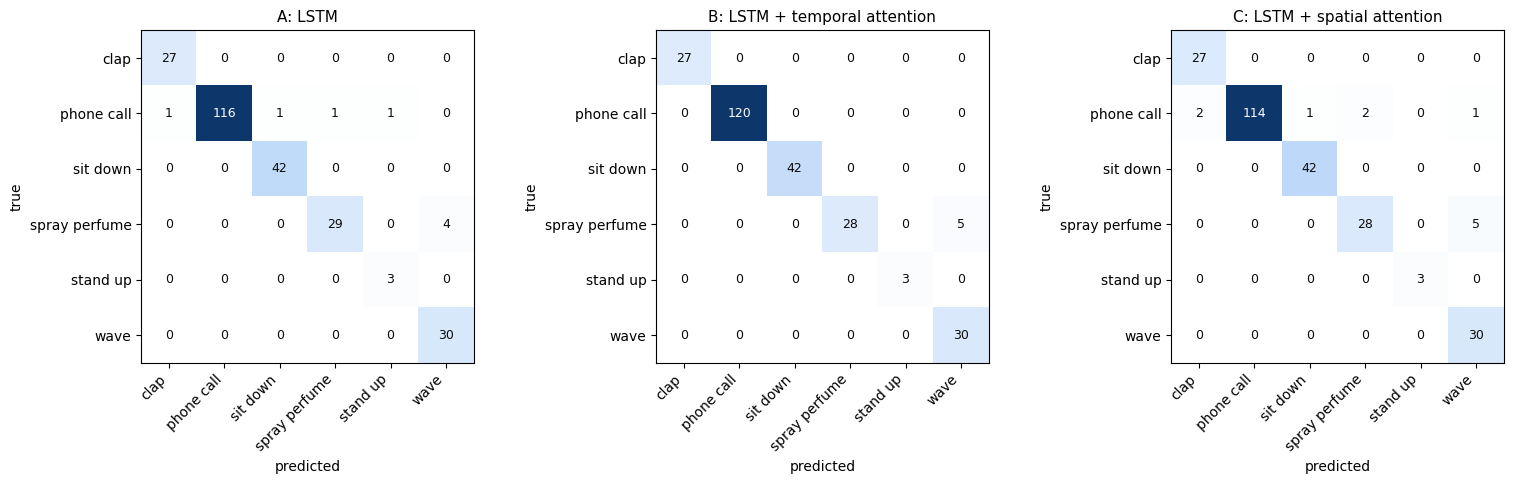

In [10]:
# Confusion matrix on the validation windows (all seeds added together).
fig, axes = plt.subplots(1, len(MODEL_CONFIGS), figsize=(5.2 * len(MODEL_CONFIGS), 4.8))
for ax, name in zip(np.atleast_1d(axes), MODEL_CONFIGS):
    cm = sum(confusion_matrix(*val_preds[(name, s)], labels=range(len(CLASSES))) for s in SEEDS)
    ax.imshow(cm, cmap=BLUE_MAP, vmin=0)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > cm.max() * 0.6 else INK)
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(name, fontsize=11)
plt.tight_layout()
plt.show()

## 9. The long video

1. Skip the first `TEST_START_SEC` seconds (camera set-up), then slide a window over the rest of the video.
2. Each window gets a probability for each of the 6 actions (average of the seeds of one model).
3. Average the probabilities over about one second, so a single odd window does not create a fake action.
4. If the best probability is still low, the window is labelled *unknown*.
5. Neighbouring windows with the same label become one segment with a start and an end time.

In [11]:
skip = int(round(TEST_START_SEC * TARGET_FPS))              # frames skipped at the beginning
test_seq = sequences["__test__"][skip:]
if len(test_seq) < WIN:
    raise RuntimeError("the analysed part of the long video is shorter than one window")
TEST_T0 = skip / TARGET_FPS                                 # real video time where the analysis starts
TEST_T1 = len(sequences["__test__"]) / TARGET_FPS           # end of the video

test_starts = np.arange(0, len(test_seq) - WIN + 1, TEST_STRIDE)
test_x = torch.from_numpy(np.stack([make_features(test_seq[s:s + WIN]) for s in test_starts]))
test_time = TEST_T0 + (test_starts + WIN / 2) / TARGET_FPS  # centre time of each window, in video seconds
STEP_SEC = TEST_STRIDE / TARGET_FPS
# time where the "territory" of each window begins (one extra entry closes the last window)
EDGE_TIME = TEST_T0 + (np.r_[test_starts, test_starts[-1] + TEST_STRIDE] + (WIN - TEST_STRIDE) / 2) / TARGET_FPS
UNKNOWN = len(CLASSES)                                      # extra label id for "unknown"
LABEL_NAMES = CLASSES + ["unknown"]


@torch.no_grad()
def predict_probs(model, x):
    # Probability of each class for every window: (n_windows, n_classes).
    model.eval()
    out = [torch.softmax(model(x[i:i + 256].to(DEVICE))[0], dim=1).cpu() for i in range(0, len(x), 256)]
    return torch.cat(out).numpy()


def postprocess(probs):
    # Probabilities -> one clean label per window (steps 3 to 5, without the times).
    k = max(1, min(len(probs), int(round(SMOOTH_SEC / STEP_SEC))))
    kernel = np.ones(k) / k
    smooth_p = np.stack([np.convolve(probs[:, c], kernel, mode="same") for c in range(probs.shape[1])], 1)
    smooth_p = smooth_p / smooth_p.sum(1, keepdims=True)
    labels = smooth_p.argmax(1)
    labels[smooth_p.max(1) < CONF_THRESHOLD] = UNKNOWN

    # merge segments that are too short into their longer neighbour
    min_len = max(1, int(round(MIN_SEGMENT_SEC / STEP_SEC)))
    while True:
        edges = np.flatnonzero(np.diff(labels)) + 1
        starts, ends = np.r_[0, edges], np.r_[edges, len(labels)]
        lengths = ends - starts
        short = np.flatnonzero(lengths < min_len)
        if len(short) == 0 or len(starts) == 1:
            break
        i = short[np.argmin(lengths[short])]                 # shortest segment first
        left = lengths[i - 1] if i > 0 else -1
        right = lengths[i + 1] if i < len(starts) - 1 else -1
        labels[starts[i]:ends[i]] = labels[starts[i - 1]] if left >= right else labels[starts[i + 1]]
    return labels


def to_segments(labels):
    # Window labels -> table of (start s, end s, action).
    edges = np.flatnonzero(np.diff(labels)) + 1
    starts, ends = np.r_[0, edges], np.r_[edges, len(labels)]
    return pd.DataFrame({
        "start (s)": np.round(EDGE_TIME[starts], 2),
        "end (s)": np.round(EDGE_TIME[ends], 2),
        "action": [LABEL_NAMES[labels[s]] for s in starts]})


test_probs = {name: {seed: predict_probs(trained[(name, seed)], test_x) for seed in SEEDS}
              for name in MODEL_CONFIGS}
test_labels = {name: postprocess(np.mean(list(test_probs[name].values()), axis=0)) for name in MODEL_CONFIGS}
timelines = {name: to_segments(test_labels[name]) for name in MODEL_CONFIGS}

for name, table in timelines.items():
    table.to_csv(os.path.join(WORK_DIR, f"timeline_model_{name[0]}.csv"), index=False)

In [12]:
# Full timeline of each model as a table.
for name, table in timelines.items():
    print(name)
    print(table.to_string(index=False), "\n")

A: LSTM
 start (s)  end (s)        action
      8.65    18.65          wave
     18.65    23.05      stand up
     23.05    31.65          clap
     31.65    37.65      stand up
     37.65    40.05          wave
     40.05    53.45    phone call
     53.45    60.25      stand up
     60.25    67.45 spray perfume
     67.45    69.65      stand up
     69.65    77.25          clap 

B: LSTM + temporal attention
 start (s)  end (s)        action
      8.65    11.05       unknown
     11.05    18.85          wave
     18.85    23.25      stand up
     23.25    31.85          clap
     31.85    37.85      stand up
     37.85    53.85    phone call
     53.85    60.25      stand up
     60.25    68.85 spray perfume
     68.85    70.85      stand up
     70.85    77.25          clap 

C: LSTM + spatial attention
 start (s)  end (s)        action
      8.65    18.85          wave
     18.85    22.85      stand up
     22.85    31.45          clap
     31.45    35.45      stand up
     35.45   

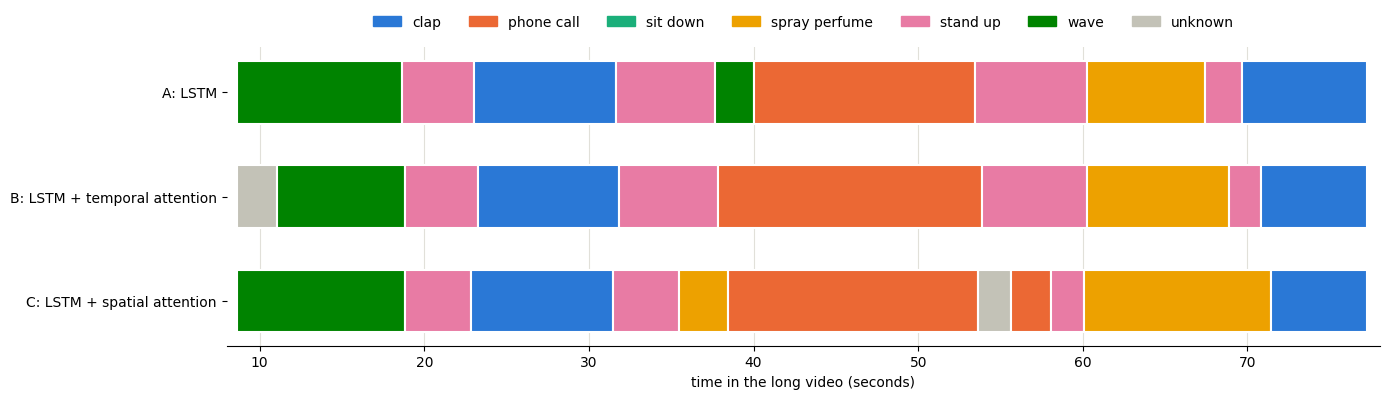

In [13]:
# The same timelines as a picture: one row per model, one colour per action.
rows_to_draw = list(timelines.items())
if GROUND_TRUTH:
    truth = pd.DataFrame(GROUND_TRUTH, columns=["start (s)", "end (s)", "action"])
    rows_to_draw = [("Ground truth", truth)] + rows_to_draw

fig, ax = plt.subplots(figsize=(14, 0.9 * len(rows_to_draw) + 1.4))
for row, (name, table) in enumerate(rows_to_draw):
    for _, seg in table.iterrows():
        ax.broken_barh([(seg["start (s)"], seg["end (s)"] - seg["start (s)"])], (row - 0.3, 0.6),
                       facecolors=CLASS_COLORS[seg["action"]], edgecolor="white", linewidth=1.5)
ax.set_yticks(range(len(rows_to_draw)), [n for n, _ in rows_to_draw])
ax.invert_yaxis()
ax.set_xlabel("time in the long video (seconds)")
ax.set_xlim(TEST_T0, TEST_T1)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.legend(handles=[Patch(color=CLASS_COLORS[c], label=c) for c in LABEL_NAMES],
          ncol=len(LABEL_NAMES), loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False)
plt.tight_layout()
plt.show()

### Scores on the long video without timings (order of the actions)

We know the *order* of the actions in the long video (`EXPECTED_ORDER`) but not their exact times, so the models are scored on the list of actions they report, in order. Standing is ignored because it can happen between any two actions.

- **precision:** of the actions the model reported, how many fit the real order.
- **recall:** of the real actions, how many the model found.
- **F1:** one number that combines precision and recall.
- **edit score:** how close the reported list is to the real list (1 = identical). This is the segment-order score used in action segmentation papers such as MS-TCN.

These numbers judge *which actions were found and in what order*, not whether each second is labelled correctly.

In [14]:
def reported_actions(table):
    # List of actions a model reported, in time order.
    #   - "stand up" and "unknown" are not counted as actions
    #   - the same action twice counts once if only "unknown" separates the two pieces
    actions, previous = [], None
    for action in table["action"]:
        if action == "unknown":
            continue
        if action != "stand up" and action != previous:
            actions.append(action)
        previous = action
    return actions


def common_in_order(a, b):
    # Length of the longest list of items that appears in both a and b in the same order.
    best = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i, x in enumerate(a, 1):
        for j, y in enumerate(b, 1):
            best[i][j] = best[i - 1][j - 1] + 1 if x == y else max(best[i - 1][j], best[i][j - 1])
    return best[-1][-1]


def edit_distance(a, b):
    # Smallest number of insert / delete / replace steps that turn list a into list b.
    row = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        new = [i]
        for j, y in enumerate(b, 1):
            new.append(min(row[j] + 1, new[j - 1] + 1, row[j - 1] + (x != y)))
        row = new
    return row[-1]


expected = [a for a in EXPECTED_ORDER if a != "stand up"]
print("Expected actions:", " -> ".join(expected), "\n")

order_rows = []
for name, table in timelines.items():
    found = reported_actions(table)
    matched = common_in_order(found, expected)
    precision = matched / len(found) if found else 0.0
    recall = matched / len(expected)
    f1 = 2 * precision * recall / (precision + recall) if matched else 0.0
    edit = 1 - edit_distance(found, expected) / max(len(found), len(expected))
    order_rows.append({"model": name, "actions reported": len(found), "correct in order": matched,
                       "order precision": precision, "order recall": recall, "order F1": f1, "edit score": edit})
    print(name)
    print("  reported:", " -> ".join(found) if found else "(nothing)", "\n")

order_scores = pd.DataFrame(order_rows).set_index("model").round(3)
order_scores.to_csv(os.path.join(WORK_DIR, "long_video_order_scores.csv"))
order_scores

Expected actions: wave -> clap -> phone call -> spray perfume -> clap 

A: LSTM
  reported: wave -> clap -> wave -> phone call -> spray perfume -> clap 

B: LSTM + temporal attention
  reported: wave -> clap -> phone call -> spray perfume -> clap 

C: LSTM + spatial attention
  reported: wave -> clap -> spray perfume -> phone call -> spray perfume -> clap 



,actions reported,correct in order,order precision,order recall,order F1,edit score
model,,,,,,
A: LSTM,6,5,0.833,1.0,0.909,0.833
B: LSTM + temporal attention,5,5,1.000,1.0,1.000,1.000
C: LSTM + spatial attention,6,5,0.833,1.0,0.909,0.833


### Optional: accuracy on the long video

This cell only works after you fill `GROUND_TRUTH` in the settings cell (section 2) with the real start and end time of each action, then re-run from section 9.

In [15]:
test_summary = None
if not GROUND_TRUTH:
    print("GROUND_TRUTH is empty, so there is no per-second accuracy for the long video yet (only the order scores above).")
else:
    # true label of each window = the action that covers the centre of the window
    true = np.full(len(test_time), -1)
    for start, end, label in GROUND_TRUTH:
        true[(test_time >= start) & (test_time < end)] = CLASSES.index(label)
    covered = true >= 0                                      # windows outside every interval are ignored
    present = np.unique(true[covered])                       # F1 is averaged over the actions that really occur

    test_rows = []
    for name in MODEL_CONFIGS:
        per_seed = []
        for seed in SEEDS:
            pred = postprocess(test_probs[name][seed])
            per_seed.append((accuracy_score(true[covered], pred[covered]),
                             f1_score(true[covered], pred[covered], average="macro",
                                      labels=present, zero_division=0)))
        acc, f1 = np.array(per_seed).T
        ens = test_labels[name]
        test_rows.append({"model": name,
                          "accuracy (mean of seeds)": acc.mean(), "accuracy (std)": acc.std(),
                          "macro F1 (mean of seeds)": f1.mean(), "macro F1 (std)": f1.std(),
                          "accuracy (seeds combined)": accuracy_score(true[covered], ens[covered]),
                          "macro F1 (seeds combined)": f1_score(true[covered], ens[covered], average="macro",
                                                                labels=present, zero_division=0)})
    test_summary = pd.DataFrame(test_rows).set_index("model").round(3)
    test_summary.to_csv(os.path.join(WORK_DIR, "long_video_scores.csv"))
    print(f"scored on {covered.sum()} of {len(covered)} windows")
    display(test_summary)

GROUND_TRUTH is empty, so there is no per-second accuracy for the long video yet (only the order scores above).


## 10. What did the attention look at?

**Model B (time).** One validation window per action. The blue line is the attention weight of each frame; the orange line is how much the body moved in that frame. Both lines add up to 1, so they are directly comparable. The grey dashed line is "every frame equally important".

**Model C (joints).** Average attention of each joint for each action. A value of 1 means an equal share; blue (above 1) means the model looked at that joint more, orange (below 1) means less.

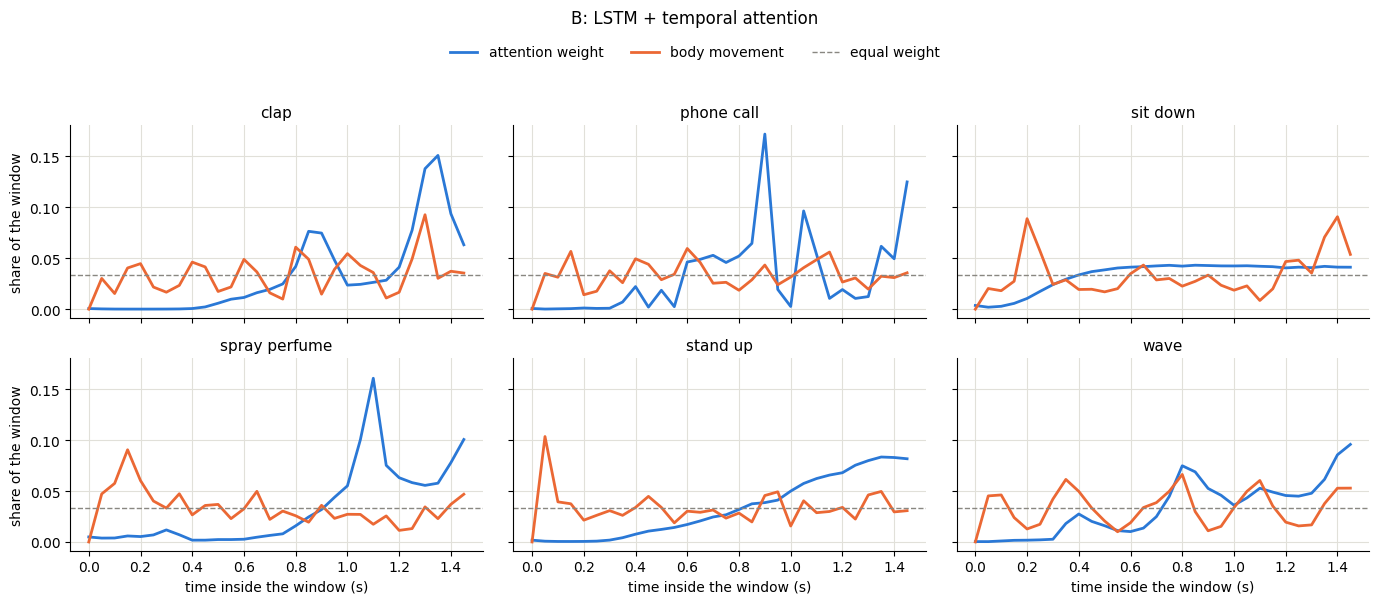

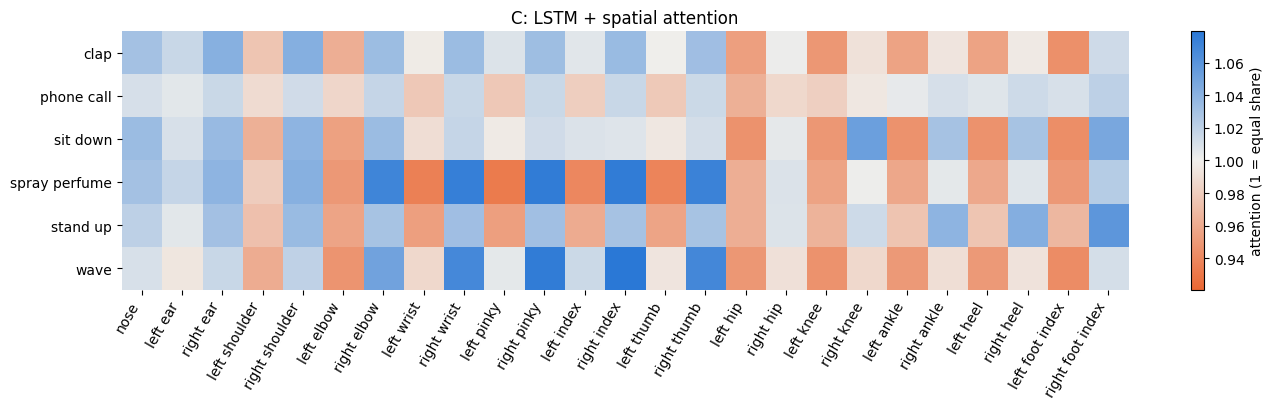

Top 3 joints per action for model C:


,1st,2nd,3rd
clap,right_shoulder,right_ear,right_index
phone call,right_foot_index,right_elbow,right_wrist
sit down,right_knee,right_foot_index,right_shoulder
spray perfume,right_pinky,right_index,right_wrist
stand up,right_foot_index,right_heel,right_ankle
wave,right_index,right_pinky,right_thumb


In [16]:
def first_window_of_class(label_id):
    # A validation window of this class. If the validation piece was too short (padded), use a training one.
    for split in ("val", "train"):
        for seg_id, start in index[split]:
            if segments[seg_id]["label"] == label_id and not segments[seg_id]["padded"]:
                return segments[seg_id]["data"][start:start + WIN]
    seg_id, start = next((s, st) for s, st in index["train"] if segments[s]["label"] == label_id)
    return segments[seg_id]["data"][start:start + WIN]


# ---------------------------------------------------------------- model B: attention over time
name_b = next((n for n, c in MODEL_CONFIGS.items() if c["temporal_att"] and not c["spatial_att"]), None)
if name_b:
    fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True, sharey=True)
    t = np.arange(WIN) / TARGET_FPS
    for ax, (label_id, label) in zip(axes.ravel(), enumerate(CLASSES)):
        win = first_window_of_class(label_id)
        x = torch.from_numpy(make_features(win))[None].to(DEVICE)
        with torch.no_grad():
            att = np.mean([trained[(name_b, s)].eval()(x)[1]["time"][0].cpu().numpy() for s in SEEDS], axis=0)
        motion = np.linalg.norm(velocity(win), axis=-1).mean(axis=1)       # movement per frame
        motion = motion / max(motion.sum(), 1e-9)
        ax.plot(t, att, color="#2a78d6", linewidth=2, label="attention weight")
        ax.plot(t, motion, color="#eb6834", linewidth=2, label="body movement")
        ax.axhline(1 / WIN, color=MUTED, linewidth=1, linestyle="--", label="equal weight")
        ax.set_title(label, fontsize=11)
        ax.grid(color=GRID, linewidth=0.8)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("time inside the window (s)")
    for ax in axes[:, 0]:
        ax.set_ylabel("share of the window")
    handles, labels_ = axes[0, 0].get_legend_handles_labels()
    fig.suptitle(name_b, y=1.0, fontsize=12)
    fig.legend(handles, labels_, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 0.96), frameon=False)
    plt.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()

# ---------------------------------------------------------------- model C: attention over joints
name_c = next((n for n, c in MODEL_CONFIGS.items() if c["spatial_att"] and not c["temporal_att"]), None)
if name_c:
    heat = np.zeros((len(CLASSES), N_JOINTS))
    for label_id in range(len(CLASSES)):
        wins = [segments[s]["data"][st:st + WIN] for split in ("val", "train") for s, st in index[split]
                if segments[s]["label"] == label_id]
        x = torch.from_numpy(np.stack([make_features(w) for w in wins])).to(DEVICE)
        with torch.no_grad():
            w = np.mean([trained[(name_c, s)].eval()(x)[1]["joint"].cpu().numpy() for s in SEEDS], axis=0)
        heat[label_id] = w.mean(axis=(0, 1)) * N_JOINTS                    # 1.0 = equal share

    # two-colour scale centred on 1: blue = more than an equal share, orange = less
    spread = max(float(np.abs(heat - 1).max()), 1e-3)
    fig, ax = plt.subplots(figsize=(14, 4.2))
    im = ax.imshow(heat, cmap=DIVERGING_MAP, aspect="auto", norm=TwoSlopeNorm(vcenter=1, vmin=1 - spread, vmax=1 + spread))
    ax.set_xticks(range(N_JOINTS), [n.replace("_", " ") for n in JOINT_NAMES], rotation=60, ha="right")
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_title(name_c, fontsize=12)
    fig.colorbar(im, ax=ax, label="attention (1 = equal share)")
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)
    plt.tight_layout()
    plt.show()

    top = pd.DataFrame({c: [JOINT_NAMES[i] for i in np.argsort(-heat[k])[:3]] for k, c in enumerate(CLASSES)},
                       index=["1st", "2nd", "3rd"]).T
    print("Top 3 joints per action for model C:")
    display(top)

## 11. Final scores

One table with everything:

- **val accuracy / val macro F1:** on the validation windows (the held-out last 30% of each training video), averaged over the seeds.
- **order precision / recall / F1 / edit score:** on the long video, from the order of the actions (section 9).
- **long video accuracy / macro F1:** per-second scores on the long video. These two columns appear only after `GROUND_TRUTH` is filled.

In [17]:
final = runs.groupby("model")[["val accuracy", "val macro F1"]].mean()
final = final.join(order_scores[["order precision", "order recall", "order F1", "edit score"]])
if test_summary is not None:
    final["long video accuracy"] = test_summary["accuracy (seeds combined)"]
    final["long video macro F1"] = test_summary["macro F1 (seeds combined)"]
final = final.round(3)
final.to_csv(os.path.join(WORK_DIR, "final_scores.csv"))
final

,val accuracy,val macro F1,order precision,order recall,order F1,edit score
model,,,,,,
A: LSTM,0.969,0.950,0.833,1.0,0.909,0.833
B: LSTM + temporal attention,0.980,0.973,1.000,1.0,1.000,1.000
C: LSTM + spatial attention,0.957,0.954,0.833,1.0,0.909,0.833


## 12. Save the results

In [18]:
runs.round(4).to_csv(os.path.join(WORK_DIR, "validation_runs.csv"), index=False)
summary.to_csv(os.path.join(WORK_DIR, "validation_summary.csv"))
for (name, seed), model in trained.items():
    torch.save(model.state_dict(), os.path.join(WORK_DIR, f"model_{name[0]}_seed{seed}.pt"))
print("saved to", WORK_DIR, ":", sorted(f for f in os.listdir(WORK_DIR) if f.endswith((".csv", ".pt"))))

saved to /kaggle/working : ['final_scores.csv', 'long_video_order_scores.csv', 'model_A_seed0.pt', 'model_A_seed1.pt', 'model_A_seed2.pt', 'model_B_seed0.pt', 'model_B_seed1.pt', 'model_B_seed2.pt', 'model_C_seed0.pt', 'model_C_seed1.pt', 'model_C_seed2.pt', 'timeline_model_A.csv', 'timeline_model_B.csv', 'timeline_model_C.csv', 'validation_runs.csv', 'validation_summary.csv']
